In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:
indoor_traits = pd.read_csv('out/v230407/broccoli_traits.csv')
indoor_traits.head()

,id,crown_height(m),center.x(m),center.y(m),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2),centroid.x(m),centroid.y(m),long_axis(m),short_axis(m),orientation(degree),crown_3dconvex_volume(cm3),crown_3dconcave_volume(cm3),crown_3dconcave_alpha,crown_roundness,head_height(m),head_3dconcave_volume(cm3),head_3dconcave_alpha
0,1-1,0.061894,0.016133,0.024035,0.077561,0.080290,51.255486,55.777778,0.014071,0.021634,0.086431,0.083233,-107.199173,186.508067,12.668349,0.015,0.738451,0.146767,1.348625,0.02
1,1-11,0.086620,0.003600,0.028051,0.103729,0.107361,86.727958,92.111111,0.000738,0.033835,0.112777,0.105936,-155.841362,454.256819,10.974741,0.025,0.755419,0.157807,12.649370,0.02
2,1-12,0.067599,-0.001300,0.042465,0.089962,0.092735,67.192994,70.777778,-0.001372,0.036533,0.096714,0.094844,-79.718065,292.259786,0.760588,0.015,0.830367,0.156621,12.200190,0.02
3,1-13,0.078768,-0.002323,0.036847,0.108976,0.105372,91.288985,97.444444,0.002538,0.041451,0.115577,0.109427,-70.754398,427.798788,17.207737,0.020,0.814435,0.160057,39.196050,0.02
4,1-15,0.089891,-0.002458,0.031097,0.120156,0.117466,115.119180,120.777778,-0.001671,0.031418,0.128480,0.121926,-144.428779,601.386847,35.102462,0.020,0.784161,0.172799,1.950164,0.02


In [3]:
len(indoor_traits)

193

In [4]:
field_traits = pd.read_csv('model2field_id.csv')
field_traits.head()

,Date,Model_ID,Field_ID,0,45,90,135
0,20220317,3-1,8574,6.00,6.46,6.39,6.66
1,20220317,3-2,8575,5.23,5.14,4.54,4.53
2,20220317,3-3,8576,4.36,4.53,4.54,4.94
3,20220317,3-4,8577,4.67,5.02,5.26,5.33
4,20220317,3-5,8578,5.62,5.70,5.32,5.88


In [5]:
field_traits['max_length'] = field_traits[['0', '45', '90', '135']].max(axis=1)
field_traits['min_length'] = field_traits[['0', '45', '90', '135']].min(axis=1)

In [6]:
field_traits = field_traits.dropna()

# indoor_traits link match

In [7]:
indoor_with_field_id = pd.merge(field_traits, indoor_traits, left_on='Model_ID', right_on='id')
indoor_with_field_id

,Date,Model_ID,Field_ID,0,45,90,135,max_length,min_length,id,...,long_axis(m),short_axis(m),orientation(degree),crown_3dconvex_volume(cm3),crown_3dconcave_volume(cm3),crown_3dconcave_alpha,crown_roundness,head_height(m),head_3dconcave_volume(cm3),head_3dconcave_alpha
0,20220317,3-1,8574,6.00,6.46,6.39,6.66,6.66,6.00,3-1,...,0.073558,0.062972,-65.296804,90.544264,31.423250,0.010,0.798339,0.142084,42.108040,0.020
1,20220317,3-2,8575,5.23,5.14,4.54,4.53,5.23,4.53,3-2,...,0.059003,0.051484,-176.139473,50.526204,25.778741,0.015,0.930713,0.149868,19.931228,0.025
2,20220317,3-3,8576,4.36,4.53,4.54,4.94,4.94,4.36,3-3,...,0.052651,0.049139,-80.964335,39.632416,14.129421,0.010,0.908292,0.147616,127.465372,0.020
3,20220317,3-4,8577,4.67,5.02,5.26,5.33,5.33,4.67,3-4,...,0.060120,0.053417,-78.029467,50.215150,18.277578,0.010,0.889342,0.146556,50.012442,0.020
4,20220317,3-5,8578,5.62,5.70,5.32,5.88,5.88,5.32,3-5,...,0.063628,0.059194,-2.246206,73.213668,32.829862,0.010,0.920256,0.156164,84.052978,0.025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183,20220405,8-32,5593,15.42,14.81,15.05,14.95,15.42,14.81,8-32,...,0.154418,0.152340,-2.194721,1091.146271,15.990872,0.020,0.744710,0.157322,49.056136,0.020
184,20220405,8-33,5594,14.91,16.69,17.63,15.70,17.63,14.91,8-33,...,0.176361,0.152302,-93.464791,1372.151591,34.448384,0.015,0.797066,0.165034,11.887970,0.020
185,20220405,9-31,10233,14.14,14.62,14.60,14.86,14.86,14.14,9-31,...,0.154003,0.142144,-62.778655,1356.690145,44.955292,0.025,0.726698,0.178237,15.085098,0.020
186,20220405,9-32,10234,15.11,14.84,14.37,14.73,15.11,14.37,9-32,...,0.152286,0.149501,-156.820172,1000.206070,42.004512,0.025,0.670645,0.181256,9.575636,0.020


In [8]:
indoor_with_field_id.columns

Index(['Date', 'Model_ID', 'Field_ID', '0', '45', '90', '135', 'max_length',
       'min_length', 'id', 'crown_height(m)', 'center.x(m)', 'center.y(m)',
       'min_rect_width(m)', 'min_rect_length(m)', 'crown_2dconvex_area(cm2)',
       'projected_leaf_area(cm2)', 'centroid.x(m)', 'centroid.y(m)',
       'long_axis(m)', 'short_axis(m)', 'orientation(degree)',
       'crown_3dconvex_volume(cm3)', 'crown_3dconcave_volume(cm3)',
       'crown_3dconcave_alpha', 'crown_roundness', 'head_height(m)',
       'head_3dconcave_volume(cm3)', 'head_3dconcave_alpha'],
      dtype='object')

In [9]:
xmax = indoor_with_field_id ['max_length'].max()
ymax = indoor_with_field_id ['long_axis(m)'].max()*100

xymax = np.ceil(max(xmax, ymax) / 5) * 5
xymax

20.0

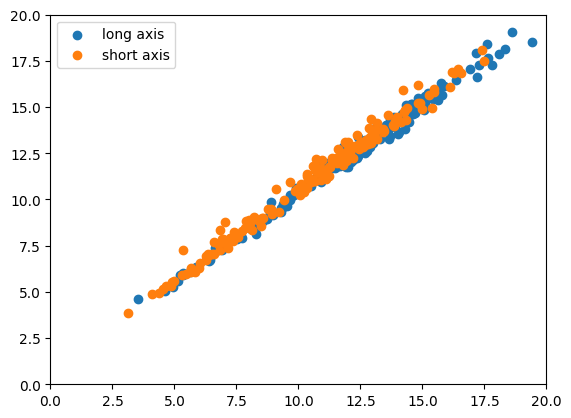

In [10]:
fig, ax = plt.subplots(1,1)

ax.scatter(
    indoor_with_field_id ['max_length'], 
    indoor_with_field_id ['long_axis(m)']*100, 
    label='long axis')
ax.scatter(
    indoor_with_field_id ['min_length'], 
    indoor_with_field_id ['short_axis(m)']*100, 
    label='short axis')


ax.set_xlim([0, xymax])
ax.set_ylim([0, xymax])

ax.legend()
plt.show()

In [11]:
from regression import *

y=0.974x+0.843  R^2=0.99
RMSE = 0.3426108615805595
-----------------
y=0.962x+0.754  R^2=0.99
RMSE = 0.29065242301644295
-----------------
y=1.022x+0.29  R^2=0.97
RMSE = 0.5527213050909145
-----------------
y=0.927x+0.386  R^2=0.98
RMSE = 0.4484924591469056
-----------------


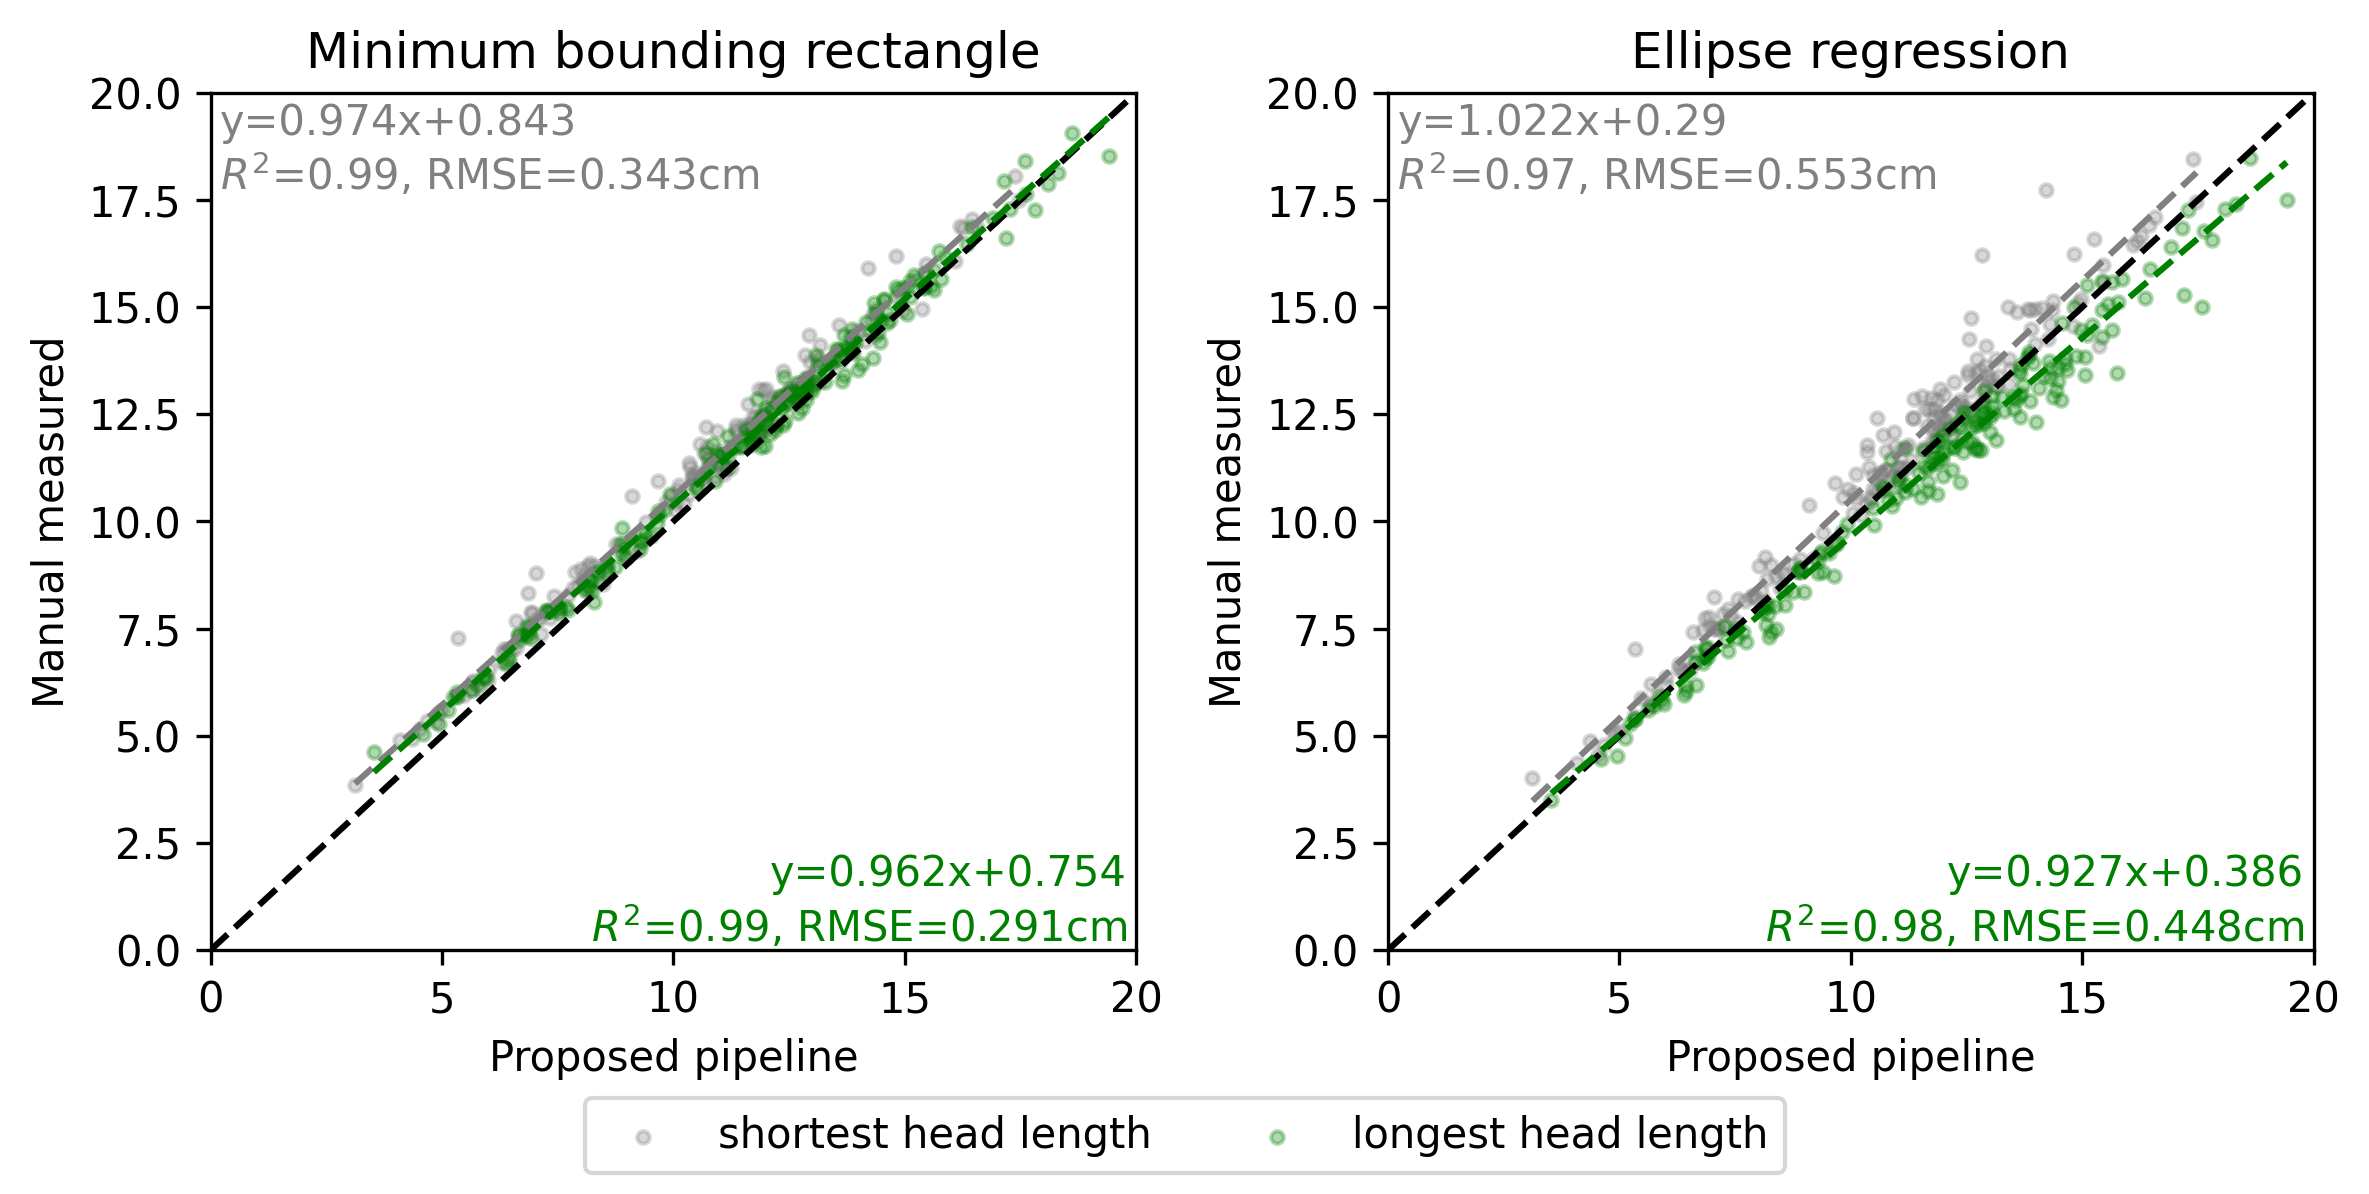

In [12]:
fig, ax = plt.subplots(1,2, figsize=(8, 4), dpi=300)

x_short = indoor_with_field_id ['min_length']
x_long  = indoor_with_field_id ['max_length']

y1_short = indoor_with_field_id ['short_axis(m)']*100
y1_long  = indoor_with_field_id ['long_axis(m)']*100

y2_short = indoor_with_field_id ['min_rect_width(m)']*100
y2_long  = indoor_with_field_id ['min_rect_length(m)']*100

ax_max = max(x_long.max(), y1_long.max(), y2_long.max())
m= np.ceil(max(xmax, ymax) / 5) * 5

y_short = [y1_short, y2_short]
y_long = [y1_long, y2_long]
titles = ['Minimum bounding rectangle', 'Ellipse regression']

for i in range(2):

    ax[i].plot([0,m], [0,m], 'k--')

    a = ax[i].scatter(x_short, y_short[i], color='gray', label='shortest length', marker='.', edgecolors=None, alpha=0.3)
    b = ax[i].scatter(x_long,  y_long[i],  color='green', label='longest length', marker='.', edgecolors=None, alpha=0.3)

    ax[i].set_xlim([0, m])
    ax[i].set_ylim([0, m])

    ax[i].set_xlabel("Proposed pipeline")
    ax[i].set_ylabel("Manual measured")


    reg_x, reg_y, y_predict, t, r2, rmse_v = linear(x_short, y_short[i])
    ax[i].plot(reg_x, reg_y, '--', c='gray')

    ax[i].text(0.01*m, 0.99*m, 
               f"y={round(t[0], 3)}x+{round(t[1], 3)}\n"
               f"$R^2$={round(r2, 2)}, RMSE={round(rmse_v, 3)}cm", 
               va='top', color='gray')

    reg_x, reg_y, y_predict, t, r2, rmse_v = linear(x_long, y_long[i])
    ax[i].plot(reg_x, reg_y, '--', c='green')

    ax[i].text(0.99*m, 0.01*m, 
               f"y={round(t[0], 3)}x+{round(t[1], 3)}\n"
               f"$R^2$={round(r2, 2)}, RMSE={round(rmse_v, 3)}cm",
               ha='right', color='green')

    ax[i].set_title(titles[i])

fig.legend([a, b], ["shortest head length", "longest head length"], loc='lower center', ncol=2)
plt.tight_layout(rect=[0,0.05,1,1])
plt.savefig("out/method_compare.pdf")
plt.show()